# 05 · June 2024 two-colour daily animation

All 30 calendar days share **identical map limits and one fixed daily colour scale**. The map only includes routed OD pairs and known bike models; displayed counts are not all recorded June trips. Set `FRAME_DPI` lower for faster generation.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from PIL import Image
ROOT=Path.cwd().resolve()
if not (ROOT/'scripts').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
from viz_routes import load,aggregate,plot,COLORS,BG
OUT=ROOT/'outputs/maps/daily_bike_type'
FRAMES=OUT/'frames'
FRAMES.mkdir(parents=True,exist_ok=True)
import pandas as pd

# Load all three months
june, routes = load(2026, 6)
july, _ = load(2026, 7)
august, _ = load(2026, 8)

trips = pd.concat(
    [june, july, august],
    ignore_index=True
)

print("Trips loaded:", f"{len(trips):,}")
print("Earliest date:", trips["date"].min())
print("Latest date:", trips["date"].max())
print("Unique dates:", trips["date"].nunique())

print("\nTrips by month:")
print(
    trips.groupby(
        pd.to_datetime(trips["date"]).dt.to_period("M")
    ).size()
)
daily=aggregate(trips,routes,daily=True)
SCALE=max(1,int(daily.n.max()))
BOUNDS=routes.total_bounds
FRAME_DPI=110
print('Mapped trips across all days:',daily.n.sum())

Trips loaded: 3,509,478
Earliest date: 2026-06-01 00:00:00
Latest date: 2026-08-31 00:00:00
Unique dates: 92

Trips by month:
date
2026-06    1112490
2026-07    1197652
2026-08    1199336
Freq: M, dtype: int64
Mapped trips across all days: 3435686


In [2]:
# Validate actual data before rendering 92 frames

trips["date"] = pd.to_datetime(trips["date"]).dt.normalize()
daily["date"] = pd.to_datetime(daily["date"]).dt.normalize()

print("Trip days:", trips["date"].nunique())
print("Mapped days:", daily["date"].nunique())

print("\nMapped trips per month:")
print(
    daily.assign(
        month=daily["date"].dt.strftime("%Y-%m")
    )
    .groupby("month")["n"]
    .sum()
)

expected = pd.date_range("2026-06-01", "2026-08-31")

mapped_days = pd.DatetimeIndex(
    daily.loc[daily["n"] > 0, "date"].unique()
).normalize()

missing = expected.difference(mapped_days)

if len(missing):
    raise ValueError(
        f"{len(missing)} days have no mapped trips. "
        f"First missing date: {missing[0]}"
    )

print("\nSUCCESS: All 92 days have mapped cycling trips!")

Trip days: 92
Mapped days: 92

Mapped trips per month:
month
2026-06    1082645
2026-07    1173684
2026-08    1179357
Name: n, dtype: int64

SUCCESS: All 92 days have mapped cycling trips!


In [3]:
# Generate daily frames for the full summer: June–August 2026

DATES = pd.date_range(
    "2026-06-01",
    "2026-08-31",
    freq="D"
)

for date in DATES:
    part = daily.loc[daily.date.eq(date)]

    fig, ax = plt.subplots(
        figsize=(11, 9),
        facecolor=BG
    )

    plot(
        ax,
        part,
        BOUNDS,
        SCALE,
        date.strftime("Toronto Bike Share | %A %B %d, %Y")
    )

    ax.legend(
        handles=[
            Line2D([0], [0], color=COLORS[k], lw=3, label=k)
            for k in ["Electric", "Conventional"]
        ],
        facecolor="#101827",
        labelcolor="white",
        loc="lower left"
    )

    ax.text(
        0.98, 0.04,
        f"Mapped trips: {part.n.sum():,}",
        transform=ax.transAxes,
        ha="right",
        color="white"
    )

    fig.savefig(
        FRAMES / f"{date:%Y-%m-%d}.png",
        dpi=FRAME_DPI,
        facecolor=fig.get_facecolor()
    )

    plt.close(fig)

    print(f"Saved {date:%Y-%m-%d}: {part.n.sum():,} mapped trips")

print(f"\nSaved {len(DATES)} frames to {FRAMES}")

Saved 2026-06-01: 30,215 mapped trips
Saved 2026-06-02: 34,358 mapped trips
Saved 2026-06-03: 37,266 mapped trips
Saved 2026-06-04: 36,438 mapped trips
Saved 2026-06-05: 35,122 mapped trips
Saved 2026-06-06: 36,811 mapped trips
Saved 2026-06-07: 37,577 mapped trips
Saved 2026-06-08: 34,667 mapped trips
Saved 2026-06-09: 35,779 mapped trips
Saved 2026-06-10: 36,337 mapped trips
Saved 2026-06-11: 34,883 mapped trips
Saved 2026-06-12: 43,359 mapped trips
Saved 2026-06-13: 45,118 mapped trips
Saved 2026-06-14: 15,719 mapped trips
Saved 2026-06-15: 32,692 mapped trips
Saved 2026-06-16: 35,484 mapped trips
Saved 2026-06-17: 31,878 mapped trips
Saved 2026-06-18: 31,330 mapped trips
Saved 2026-06-19: 37,489 mapped trips
Saved 2026-06-20: 43,047 mapped trips
Saved 2026-06-21: 36,405 mapped trips
Saved 2026-06-22: 28,560 mapped trips
Saved 2026-06-23: 41,290 mapped trips
Saved 2026-06-24: 40,993 mapped trips
Saved 2026-06-25: 32,104 mapped trips
Saved 2026-06-26: 38,576 mapped trips
Saved 2026-0

In [4]:
print("First date:", trips["date"].min())
print("Last date:", trips["date"].max())
print("Unique days:", trips["date"].nunique())

print("Mapped trips by month:")
print(
    daily.assign(
        month=pd.to_datetime(daily["date"]).dt.strftime("%Y-%m")
    ).groupby("month")["n"].sum()
)

First date: 2026-06-01 00:00:00
Last date: 2026-08-31 00:00:00
Unique days: 92
Mapped trips by month:
month
2026-06    1082645
2026-07    1173684
2026-08    1179357
Name: n, dtype: int64


In [5]:
from PIL import Image

files = [
    FRAMES / f"{date:%Y-%m-%d}.png"
    for date in DATES
]

gif_path = FRAMES.parent / "june-august_2026_ebike_conventional.gif"

images = [Image.open(f).convert("RGB") for f in files]

images[0].save(
    gif_path,
    save_all=True,
    append_images=images[1:],
    duration=650,
    loop=0,
    optimize=True
)

for im in images:
    im.close()

print("Saved:", gif_path)
print("Total frames:", len(files))

Saved: /scratch/project_2010417/paper3/toronto-bikeshare-viz/outputs/maps/daily_bike_type/june-august_2026_ebike_conventional.gif
Total frames: 92


First date: 2026-06-01 00:00:00
Last date: 2026-08-31 00:00:00
Days represented: 92


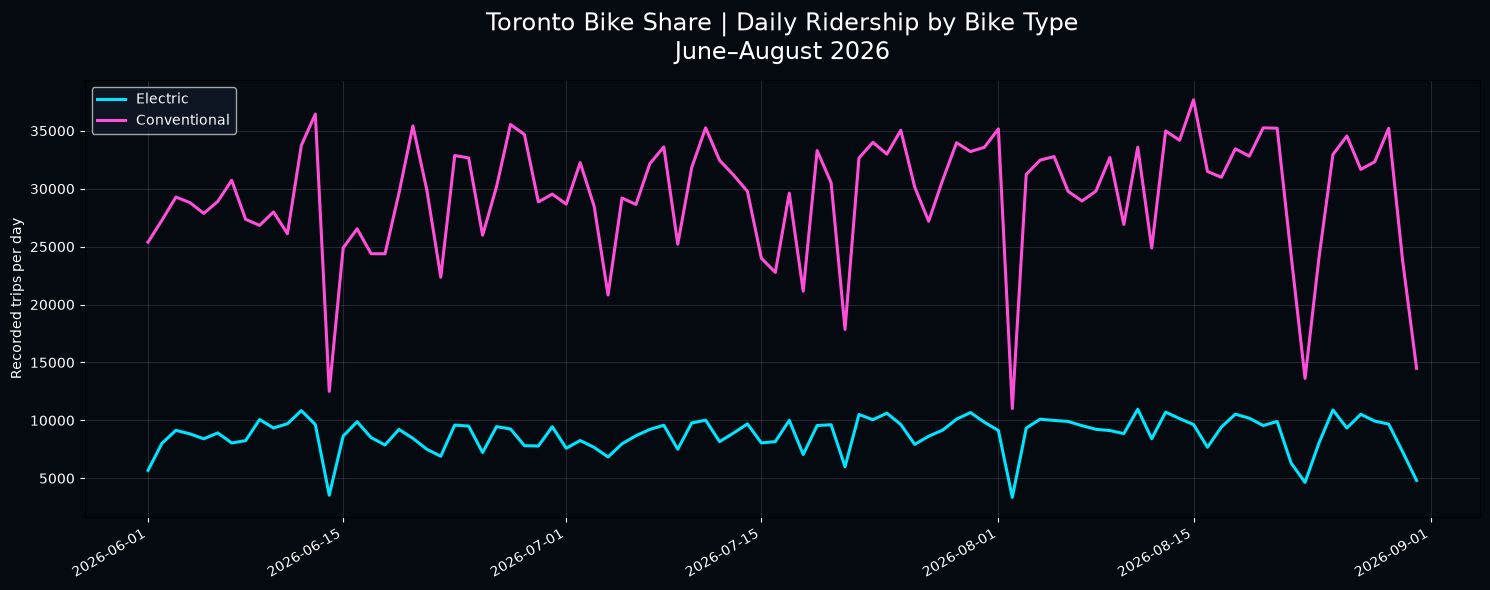

In [6]:
# Count recorded trips by day and bicycle type
counts = (
    trips.groupby(["date", "bike_type"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

# Verify full summer coverage
print("First date:", counts.index.min())
print("Last date:", counts.index.max())
print("Days represented:", len(counts))

# Plot daily counts
fig, ax = plt.subplots(figsize=(15, 6), facecolor=BG)
ax.set_facecolor(BG)

for kind, color in COLORS.items():
    if kind in counts.columns:
        ax.plot(
            counts.index,
            counts[kind],
            label=kind,
            color=color,
            linewidth=2.2
        )

ax.set_title(
    "Toronto Bike Share | Daily Ridership by Bike Type\n"
    "June–August 2026",
    color="white",
    fontsize=17,
    pad=15
)

ax.set_ylabel("Recorded trips per day", color="white")
ax.tick_params(colors="white")
ax.grid(color="white", alpha=0.12)

ax.legend(
    labelcolor="white",
    facecolor="#101827"
)

fig.autofmt_xdate()
fig.tight_layout()

fig.savefig(
    OUT / "summer_2026_daily_counts_by_bike_type.png",
    dpi=200,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight"
)

plt.show()

In [7]:
print("Trip days:", trips["date"].nunique())
print("Mapped days:", daily["date"].nunique())

print(
    daily.groupby(
        pd.to_datetime(daily["date"]).dt.strftime("%Y-%m")
    )["n"].sum()
)

Trip days: 92
Mapped days: 92
date
2026-06    1082645
2026-07    1173684
2026-08    1179357
Name: n, dtype: int64
